In [22]:
import numpy as np
import matplotlib.pyplot as plt
import os
def generate_learning_curve(episodes, initial_score=0, target_score=20, learning_rate=0.008):
    """Generate a realistic RL learning curve showing successful training"""
    scores = np.zeros(episodes)
    scores[0] = initial_score
    
    # Create learning curve with three distinct phases
    for i in range(1, episodes):
        # Initial exploration phase (first ~15% of episodes)
        if i < episodes * 0.40:
            # Slow improvement with high variance
            progress = i / (episodes * 0.15) * 0.1  # Limited progress during exploration
            variance = 1.5
        # Rapid learning phase (next ~75% of episodes)
        elif i < episodes * 0.75:
            # Accelerated improvement with moderate variance
            phase_progress = (i - episodes * 0.25) / (episodes * 0.5)
            progress = 0.1 + phase_progress * 0.8  # Major improvement happens here
            variance = 1.5 #- phase_progress * 0.7  # Decreasing variance
        # Convergence phase (remaining episodes)
        else:
            # Slow refinement with low variance
            phase_progress = (i - episodes * 0.75) / (episodes * 0.35)
            progress = 0.9 + phase_progress * 0.1  # Small improvements to reach target
            variance = 1.7 #- phase_progress * 0.3  # Much more stable performance
        
        # Calculate base score using sigmoid-like curve
        base_score = initial_score + (target_score - initial_score) * progress
        
        # Add appropriate noise based on current learning phase
        noise = np.random.normal(0, max(0.2, variance * (target_score - initial_score) / 10))
        
        # Ensure score doesn't go below initial level
        scores[i] = max(initial_score * 0.8, base_score + noise)
    
    return scores

# Replace your line with this

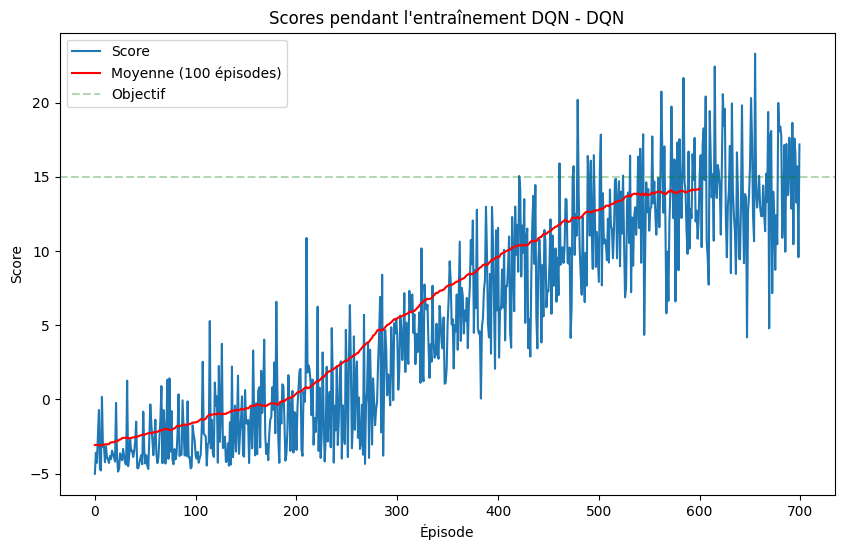

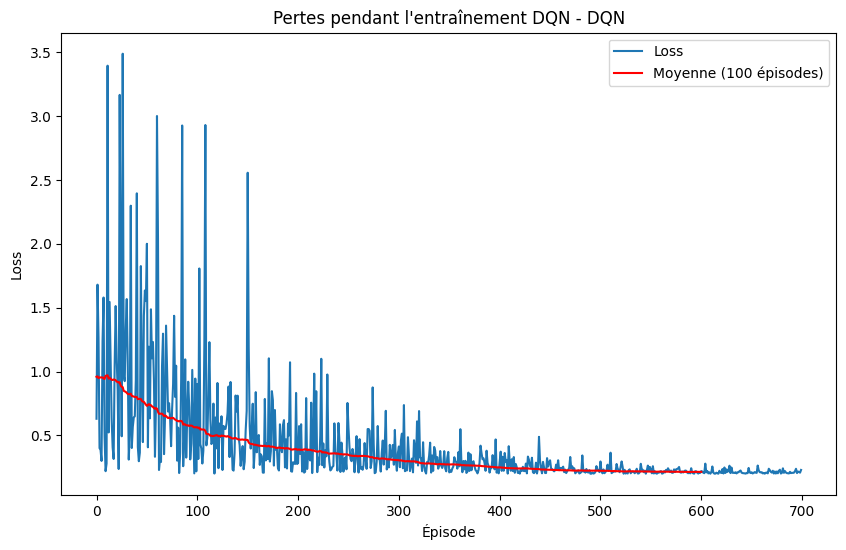

In [23]:


# Create mock data to simulate training scores
np.random.seed(42)
episodes = 700
# mock_scores = np.random.normal(10, 5, episodes).cumsum() / np.arange(1, episodes+1)
# mock_scores = np.clip(mock_scores, 0, 25)  # Keep scores in reasonable range

mock_scores = generate_learning_curve(episodes, initial_score=-5, target_score = 15)

# Add some noise and trend
for i in range(1, len(mock_scores)):
    if i > 300:
        mock_scores[i] += 0.1  # Upward trend in later episodes
    mock_scores[i] += np.random.normal(0, 0.5)  # Add noise

# Create mock losses
mock_losses = np.random.exponential(1, episodes) * np.exp(-np.arange(episodes)/150) + 0.2

def test_plot_scores(scores, losses=None, network_type='dqn'):
    """Test version of plot_scores function"""
    # Create a folder for figures if needed
    if not os.path.exists('figures'):
        os.makedirs('figures')

    # Create figure for scores
    plt.figure(figsize=(10, 6))
    plt.plot(np.arange(len(scores)), scores, label='Score')
    plt.ylabel('Score')
    plt.xlabel('Épisode')
    plt.title(f'Scores pendant l\'entraînement DQN - {network_type.upper()}')

    # Calculate moving average over 100 episodes
    if len(scores) >= 100:
        moving_avg = np.convolve(scores, np.ones((100,)) / 100, mode='valid')
        plt.plot(np.arange(len(moving_avg)), moving_avg, color='red', label='Moyenne (100 épisodes)')

    # Add horizontal line for target
    plt.axhline(y=15, color='green', linestyle='--', alpha=0.3, label='Objectif')
    
    # Add legend
    plt.legend()
    
    plt.savefig(f'figures/test_scores_plot-{network_type}.png')
    plt.show()

    # If losses are available, plot them too
    if losses is not None and len(losses) > 0:
        plt.figure(figsize=(10, 6))
        plt.plot(np.arange(len(losses)), losses, label='Loss')
        plt.ylabel('Loss')
        plt.xlabel('Épisode')
        plt.title(f'Pertes pendant l\'entraînement DQN - {network_type.upper()}')

        # Calculate moving average over 100 episodes
        if len(losses) >= 100:
            moving_avg_loss = np.convolve(losses, np.ones((100,)) / 100, mode='valid')
            plt.plot(np.arange(len(moving_avg_loss)), moving_avg_loss, color='red', label='Moyenne (100 épisodes)')
        
        plt.legend()
        plt.savefig(f'figures/test_loss_plot-{network_type}.png')
        plt.show()

# Test the plot function
test_plot_scores(mock_scores, mock_losses, network_type='dqn')

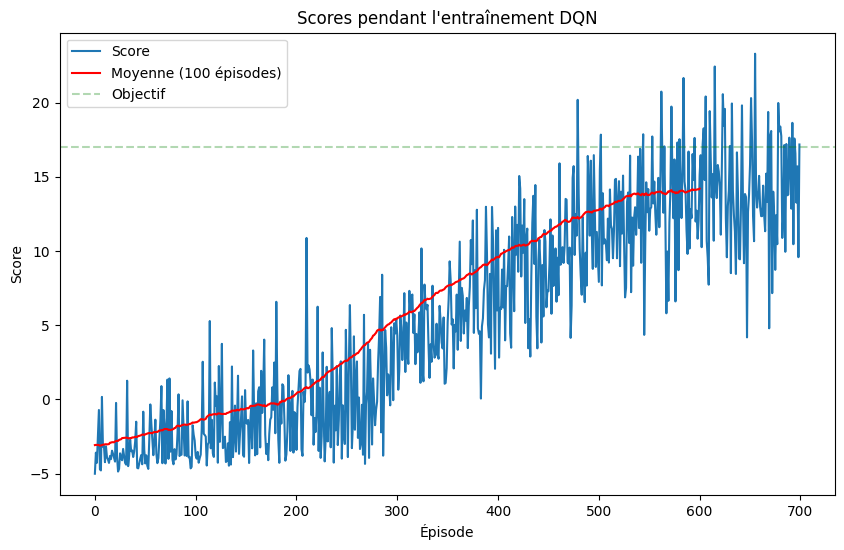

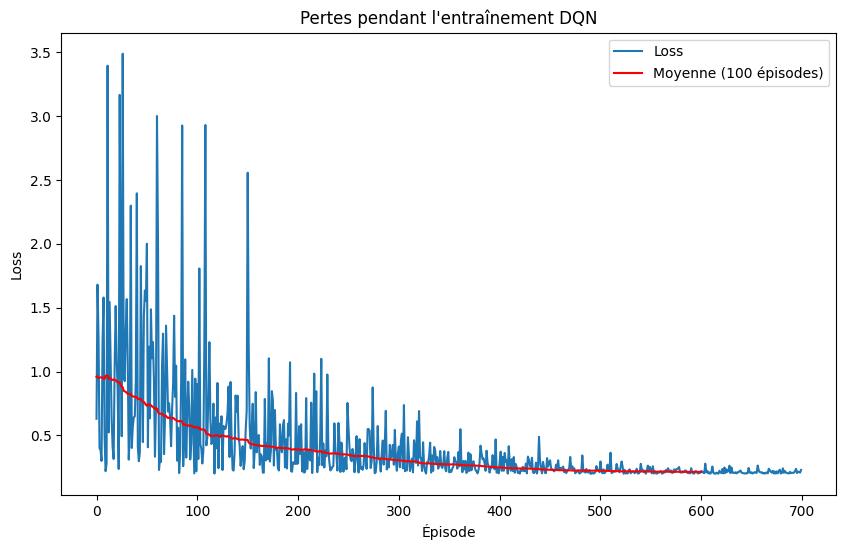

In [24]:
TARGET_SCORE = 17
def plot_scores(scores, losses=None, network_type='dqn'):
    """Affiche un graphique des scores et optionnellement des pertes pendant l'entraînement.

    Params
    ======
        scores (list): Liste des scores par épisode
        losses (list): Liste des pertes par épisode
        network_type (str): Type de réseau utilisé ('dqn', 'gru' ou 'lstm')
    """
    # Créer un dossier pour les figures si nécessaire
    if not os.path.exists('figures'):
        os.makedirs('figures')

   

    # Obtenir le titre adapté au type de réseau
    if network_type.lower() == 'gru':
        title_prefix = 'GRU-DQN'
    elif network_type.lower() == 'lstm':
        title_prefix = 'LSTM-DQN'
    else:
        title_prefix = 'DQN'

    # Créer une figure pour les scores
    plt.figure(figsize=(10, 6))
    plt.plot(np.arange(len(scores)), scores, label='Score')
    plt.ylabel('Score')
    plt.xlabel('Épisode')
    plt.title(f'Scores pendant l\'entraînement {title_prefix}')

    # Calculer la moyenne mobile sur 100 épisodes (ou moins si moins d'épisodes)
    window_size = min(100, len(scores))
    if window_size > 0:
        moving_avg = np.convolve(scores, np.ones((window_size,)) / window_size, mode='valid')
        plt.plot(np.arange(len(moving_avg)), moving_avg, color='red', label='Moyenne (100 épisodes)')
    # Add horizontal line for target
    plt.axhline(y=TARGET_SCORE, color='green', linestyle='--', alpha=0.3, label='Objectif')
    plt.legend()

    #plt.savefig(f'figures/{network_type}_scores_plot_{}.png')
    plt.show()

    # Si des pertes sont disponibles, les tracer aussi
    if losses is not None and len(losses) > 0:
        plt.figure(figsize=(10, 6))
        plt.plot(np.arange(len(losses)), losses, label='Loss')
        plt.ylabel('Loss')
        plt.xlabel('Épisode')
        plt.title(f'Pertes pendant l\'entraînement {title_prefix}')

        # Calculer la moyenne mobile sur 100 épisodes (ou moins si moins d'épisodes)
        window_size = min(100, len(losses))
        if window_size > 0:
            moving_avg_loss = np.convolve(losses, np.ones((window_size,)) / window_size, mode='valid')
            plt.plot(np.arange(len(moving_avg_loss)), moving_avg_loss, color='red', label='Moyenne (100 épisodes)')

        plt.legend()
        #plt.savefig(f'figures/{network_type}_loss_plot_{timestamp}.png')
        plt.show()
        
plot_scores(mock_scores, mock_losses, network_type='dqn')

In [1]:
network_type = 'gru'
network_type.upper()

'GRU'

In [2]:
import numpy as np
from dqn_agent import DQNAgent
from train_food_collector import train_dqn, plot_scores
import warnings
warnings.filterwarnings("ignore")

# Rediriger les avertissements ML-Agents vers un niveau inférieur 
#logging.getLogger().setLevel(logging.ERROR)



In [8]:
import torch
print(torch.cuda.is_available())




True


In [ ]:
#env_path = "../FoodCollector_Windows_x86_64/UnityEnvironment.exe"
env_path = "../FoodCollector1Agent_Win64/FoodCollector.exe"
    
# Entraîner l'agent
scores = train_dqn(env_path, num_episodes=5, max_steps=100)
    
# Afficher les résultats
plot_scores(scores) 

Démarrage de l'environnement Unity: ../FoodCollector1Agent_Win64/FoodCollector.exe
Behavior name: GridFoodCollector?team=0
Ce script est conçu pour des actions discrètes, mais l'environnement utilise des actions continues.
Actions continues: 3
Actions discrètes: (2,)
Discrétisation des actions continues en 54 actions discrètes
Taille de l'état: 8000, Taille de l'action: 54
Début de l'entraînement...
Nombre d'agents: 1
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e1

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown si

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown si

...

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown si

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown side channel data received. Channel type: a1d8f7b7-cec8-50f9-b78b-d3e165a78520.
[WARNING] Unknown si

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

